# Pakistan Housing Market — Exploratory Data Analysis

**Goal:** understand what drives listing prices in Pakistan's five largest property markets, and how the sale and rental markets differ by city, property type, size and neighbourhood.

**Questions this notebook answers**

1. What does the market look like — which cities and property types dominate the listings?
2. How do sale prices and rents differ between cities and property types?
3. How strongly do size, bedrooms and bathrooms relate to price?
4. Which neighbourhoods are the most expensive and the most affordable per unit of land?
5. Where does renting out a property pay back fastest (gross rental yield)?

**Data:** property listings from the Kaggle dataset [House Prices 2023 Dataset](https://www.kaggle.com/datasets/howisusmanali/house-prices-2023-dataset/data).
This notebook starts from `Cleaned_data_for_model.csv`, a pre-cleaned extract of that dataset in which every area is already expressed in a single unit (Marla).

**Units:** prices are in Pakistani Rupees (PKR). Area is in Marla (1 Kanal = 20 Marla).

## 1. Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

# One colour per entity, used consistently in every chart
SALE, RENT = "#2a78d6", "#eb6834"
PURPOSE_COLORS = {"For Sale": SALE, "For Rent": RENT}
TYPE_COLORS = {"House": "#1baf7a", "Flat": "#4a3aa7"}
SEGMENT_COLORS = ["#86b6ef", "#2a78d6", "#104281"]   # light -> dark = budget -> premium
SECONDARY, MUTED = "#52514e", "#898781"

plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "figure.dpi": 110, "font.size": 10,
    "axes.edgecolor": "#c3c2b7", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlepad": 12,
    "axes.labelcolor": SECONDARY, "xtick.color": MUTED, "ytick.color": MUTED,
    "legend.frameon": False,
})


def label_bars(ax, fmt="{:,.0f}"):
    """Write the value at the end of every bar."""
    for container in ax.containers:
        ax.bar_label(container, labels=[fmt.format(v) for v in container.datavalues],
                     padding=3, fontsize=9, color=SECONDARY)


def horizontal(ax):
    """Styling for horizontal bar charts: value grid only, no axis titles."""
    ax.grid(axis="y", visible=False)
    ax.set_ylabel("")
    ax.margins(x=0.12)

## 2. Load and understand the data

In [2]:
df_raw = pd.read_csv("Cleaned_data_for_model.csv")
print(f"{df_raw.shape[0]:,} rows x {df_raw.shape[1]} columns")
df_raw.head()

99,499 rows x 9 columns


,Unnamed: 0,property_type,price,location,city,baths,purpose,bedrooms,Area_in_Marla
0,0,Flat,10000000,G-10,Islamabad,2,For Sale,2,4.00
1,1,Flat,6900000,E-11,Islamabad,3,For Sale,3,5.60
2,2,House,16500000,G-15,Islamabad,6,For Sale,5,8.00
3,3,House,43500000,Bani Gala,Islamabad,4,For Sale,4,40.00
4,4,House,7000000,DHA Defence,Islamabad,3,For Sale,3,8.00


`Unnamed: 0` is the row number from the original Kaggle file, so it is kept as a listing id rather than dropped.

In [3]:
df = df_raw.rename(columns={"Unnamed: 0": "listing_id", "Area_in_Marla": "area_marla"})
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 99499 entries, 0 to 99498
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   listing_id     99499 non-null  int64  
 1   property_type  99499 non-null  str    
 2   price          99499 non-null  int64  
 3   location       99499 non-null  str    
 4   city           99499 non-null  str    
 5   baths          99499 non-null  int64  
 6   purpose        99499 non-null  str    
 7   bedrooms       99499 non-null  int64  
 8   area_marla     99499 non-null  float64
dtypes: float64(1), int64(4), str(4)
memory usage: 6.8 MB


In [4]:
df[["price", "baths", "bedrooms", "area_marla"]].describe()

,price,baths,bedrooms,area_marla
count,"99,499.00","99,499.00","99,499.00","99,499.00"
mean,"10,375,919.50",3.53,3.35,8.76
std,"10,659,998.26",1.47,1.26,7.47
min,"15,500.00",1.00,0.00,0.00
25%,"150,000.00",2.00,2.00,4.80
50%,"7,500,000.00",3.00,3.00,6.70
75%,"15,500,000.00",5.00,4.00,10.00
max,"44,900,000.00",7.00,6.00,194.00


In [5]:
cat_cols = ["property_type", "city", "purpose", "location"]
pd.DataFrame({
    "unique values": df[cat_cols].nunique(),
    "most common": df[cat_cols].mode().iloc[0],
    "share of most common (%)": [df[c].value_counts(normalize=True).iloc[0] * 100 for c in cat_cols],
})

,unique values,most common,share of most common (%)
property_type,7,House,58.46
city,5,Karachi,37.25
purpose,2,For Sale,71.30
location,1389,DHA Defence,11.85


**First observations**

- The price column mixes two very different things: sale prices (millions of PKR) and monthly rents (tens of thousands of PKR). Any average over the whole column is meaningless, so **every price analysis below is done separately for sale and rent**.
- `location` has well over a thousand values and some names (for example *Bahria Town*, *DHA Defence*) exist in more than one city, so neighbourhoods are always identified by city **and** location.

## 3. Data quality checks

In [6]:
is_sale = df["purpose"] == "For Sale"

checks = pd.Series({
    "missing values": int(df.isnull().sum().sum()),
    "duplicate rows": int(df.duplicated().sum()),
    "area below 1 Marla": int((df["area_marla"] < 1).sum()),
    "sale listings priced below PKR 500k": int((is_sale & (df["price"] < 500_000)).sum()),
    "rent listings priced above PKR 1M / month": int((~is_sale & (df["price"] > 1_000_000)).sum()),
    "listings with 0 bedrooms": int((df["bedrooms"] == 0).sum()),
}, name="rows")
checks.to_frame()

,rows
missing values,0
duplicate rows,0
area below 1 Marla,62
sale listings priced below PKR 500k,71
rent listings priced above PKR 1M / month,43
listings with 0 bedrooms,294


In [7]:
# Which property types report 0 bedrooms?
df.loc[df["bedrooms"] == 0, "property_type"].value_counts().to_frame("listings with 0 bedrooms")

,listings with 0 bedrooms
property_type,
House,139
Flat,119
Lower Portion,15
Upper Portion,14
Room,6
Penthouse,1


**Decisions**

| Issue | Action | Why |
|---|---|---|
| Area below 1 Marla | removed | Not a plausible plot size (1 Marla is about 25 m²); these are data-entry errors and they distort price per Marla. |
| Sale price below PKR 500k | removed | Far below the rest of the sale market — almost certainly rents entered as sales. |
| Rent above PKR 1M per month | removed | Far above the rest of the rental market — almost certainly sale prices entered as rents. |
| 0 bedrooms | kept | A small group, and the price and area of these listings look normal. They are excluded only from the bedroom chart. |

The source file is not modified — the filter is applied in memory only.

In [8]:
bad = (
    (df["area_marla"] < 1)
    | (is_sale & (df["price"] < 500_000))
    | (~is_sale & (df["price"] > 1_000_000))
)
print(f"Removed {bad.sum():,} of {len(df):,} rows ({bad.mean():.2%})")

df = df[~bad].reset_index(drop=True)
df.shape

Removed 176 of 99,499 rows (0.18%)


(99323, 9)

## 4. Feature engineering

In [9]:
# Price per Marla makes properties of different sizes comparable
df["price_per_marla"] = df["price"] / df["area_marla"]

sale = df[df["purpose"] == "For Sale"].copy()
rent = df[df["purpose"] == "For Rent"].copy()

# Split the sale market into three equal-sized segments by price per Marla
sale["segment"] = pd.qcut(sale["price_per_marla"], q=3, labels=["Budget", "Mid-range", "Premium"])

print(f"For sale: {len(sale):,} listings   |   For rent: {len(rent):,} listings")
sale.groupby("segment", observed=True)["price_per_marla"].agg(["min", "max", "count"])

For sale: 70,861 listings   |   For rent: 28,462 listings


,min,max,count
segment,,,
Budget,"13,043.48","1,575,000.00",23653
Mid-range,"1,575,342.47","2,200,000.00",23853
Premium,"2,201,086.96","42,500,000.00",23355


## 5. What does the market look like?

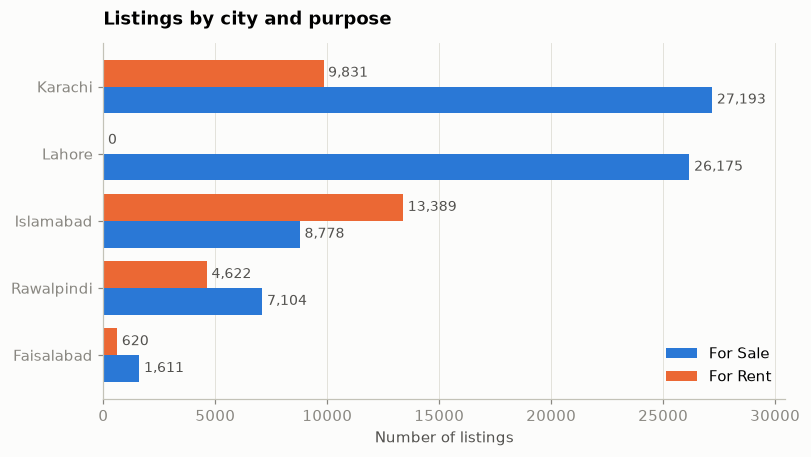

In [10]:
by_city = (df.groupby(["city", "purpose"]).size().unstack(fill_value=0)
            [["For Sale", "For Rent"]].sort_values("For Sale"))

ax = by_city.plot(kind="barh", figsize=(8, 4.2), width=0.8,
                  color=[PURPOSE_COLORS[c] for c in by_city.columns])
label_bars(ax)
horizontal(ax)
ax.set_title("Listings by city and purpose")
ax.set_xlabel("Number of listings")
ax.legend(title="", loc="lower right")
plt.show()

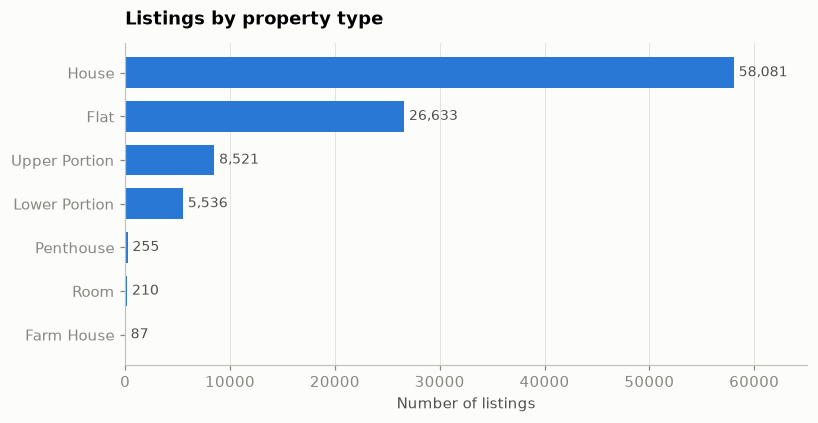

In [11]:
by_type = df["property_type"].value_counts().sort_values()

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.barh(by_type.index, by_type.values, color=SALE, height=0.7)
label_bars(ax)
horizontal(ax)
ax.set_title("Listings by property type")
ax.set_xlabel("Number of listings")
plt.show()

**What this shows**

- Karachi and Lahore have the most listings (37,024 and 26,175); Faisalabad is by far the smallest market (2,231).
- **Lahore has no rental listings at all in this extract**, so it is absent from every rent comparison below. That is a gap in the data, not a fact about the city.
- Islamabad is the only city where rentals outnumber sales (60% of its listings are for rent).
- Houses (58%) and flats (27%) make up 85% of all listings. Upper and lower portions are mostly a rental product (81% and 88% of them are for rent).

## 6. How are prices distributed?

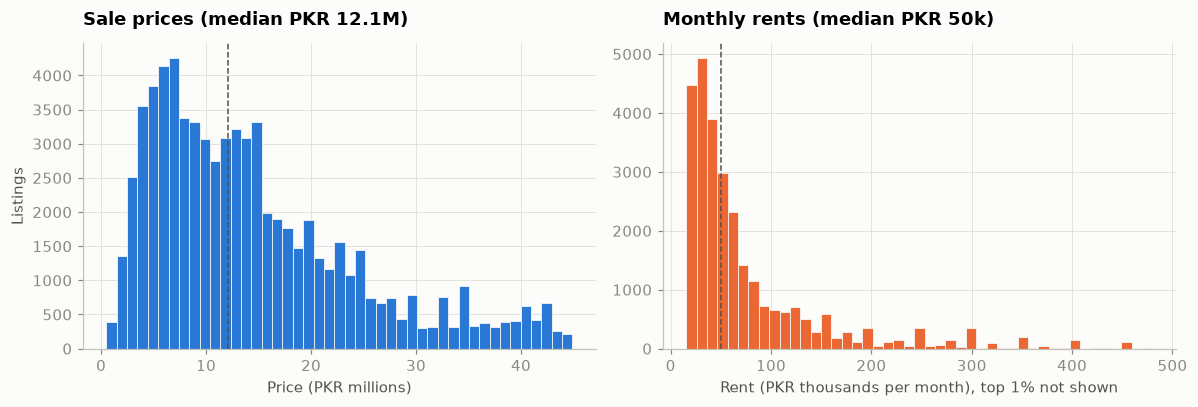

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))

axes[0].hist(sale["price"] / 1e6, bins=45, color=SALE, edgecolor="#fcfcfb", linewidth=0.5)
axes[0].axvline(sale["price"].median() / 1e6, color=SECONDARY, linestyle="--", linewidth=1)
axes[0].set_title(f"Sale prices (median PKR {sale['price'].median() / 1e6:.1f}M)")
axes[0].set_xlabel("Price (PKR millions)")
axes[0].set_ylabel("Listings")

rent_cap = rent["price"].quantile(0.99)   # the top 1% is cut from the chart only, to keep it readable
axes[1].hist(rent.loc[rent["price"] <= rent_cap, "price"] / 1e3, bins=45, color=RENT,
             edgecolor="#fcfcfb", linewidth=0.5)
axes[1].axvline(rent["price"].median() / 1e3, color=SECONDARY, linestyle="--", linewidth=1)
axes[1].set_title(f"Monthly rents (median PKR {rent['price'].median() / 1e3:.0f}k)")
axes[1].set_xlabel("Rent (PKR thousands per month), top 1% not shown")

plt.tight_layout()
plt.show()

Both distributions are right-skewed: most listings sit at the low end with a long tail of expensive properties. Because of that skew, the **median** is used as the typical price in the rest of the notebook instead of the mean.

The sale distribution stops abruptly near PKR 45M. That is a property of this cleaned extract (very expensive listings were removed upstream), so the conclusions here describe the mainstream market, not the luxury end.

## 7. Prices by city

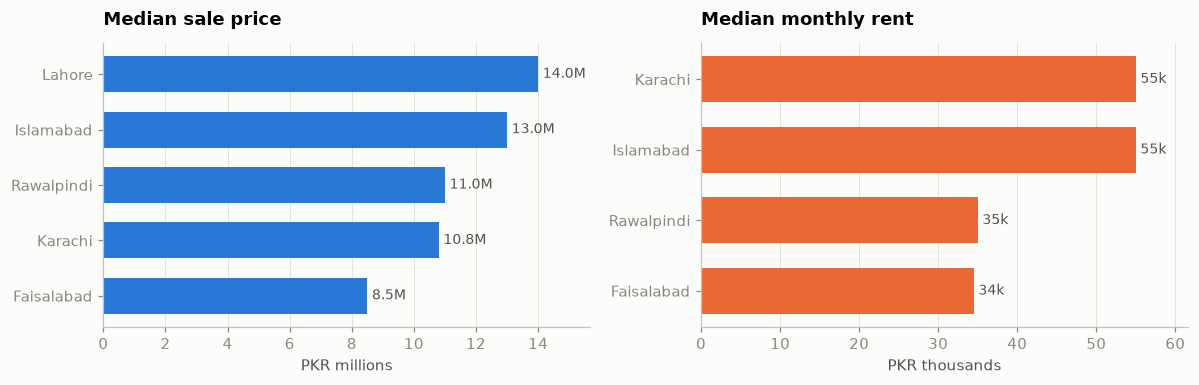

In [13]:
city_sale = sale.groupby("city")["price"].median().sort_values() / 1e6
city_rent = rent.groupby("city")["price"].median().sort_values() / 1e3

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].barh(city_sale.index, city_sale.values, color=SALE, height=0.65)
axes[0].set_title("Median sale price")
axes[0].set_xlabel("PKR millions")
label_bars(axes[0], "{:.1f}M")

axes[1].barh(city_rent.index, city_rent.values, color=RENT, height=0.65)
axes[1].set_title("Median monthly rent")
axes[1].set_xlabel("PKR thousands")
label_bars(axes[1], "{:.0f}k")

for ax in axes:
    horizontal(ax)
plt.tight_layout()
plt.show()

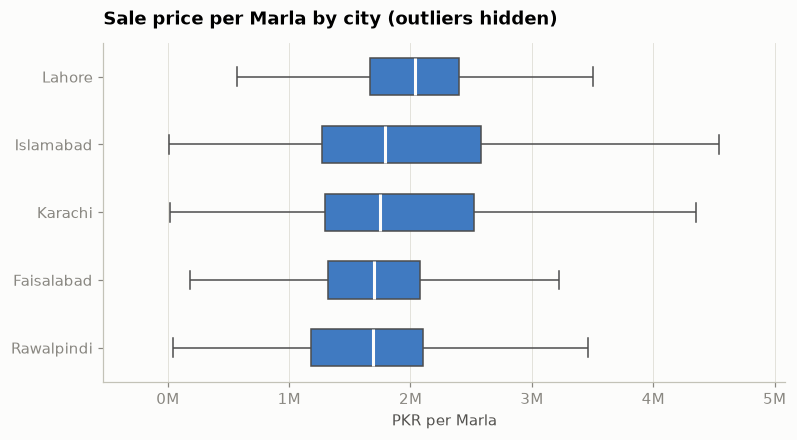

,listings,median_price,median_area_marla,median_price_per_marla
city,,,,
Lahore,26175,"14,000,000.00",6.00,"2,040,000.00"
Islamabad,8778,"13,000,000.00",6.00,"1,792,778.14"
Karachi,27193,"10,800,000.00",5.30,"1,750,000.00"
Faisalabad,1611,"8,500,000.00",5.00,"1,700,000.00"
Rawalpindi,7104,"11,000,000.00",6.00,"1,687,500.00"


In [14]:
# Total price depends on how big the typical property is, so compare price per Marla as well
city_order = sale.groupby("city")["price_per_marla"].median().sort_values(ascending=False).index

fig, ax = plt.subplots(figsize=(8, 4))
sns.boxplot(data=sale, x="price_per_marla", y="city", order=city_order, color=SALE,
            showfliers=False, width=0.55, linewidth=1, ax=ax,
            medianprops={"color": "#fcfcfb", "linewidth": 2})
ax.xaxis.set_major_formatter(lambda v, _: f"{v / 1e6:.0f}M")
horizontal(ax)
ax.set_title("Sale price per Marla by city (outliers hidden)")
ax.set_xlabel("PKR per Marla")
plt.show()

sale.groupby("city").agg(listings=("price", "size"),
                         median_price=("price", "median"),
                         median_area_marla=("area_marla", "median"),
                         median_price_per_marla=("price_per_marla", "median")).loc[city_order]

**What this shows**

- By total price, Lahore is the most expensive city to buy in (median PKR 14.0M) and Faisalabad the cheapest (PKR 8.5M).
- Lahore also leads per Marla (PKR 2.0M), so its higher prices are not just a matter of bigger plots. The other four cities are much closer to each other on this measure: PKR 1.69M to 1.79M per Marla.
- Faisalabad has the lowest total price mainly because its properties are smaller (median 5.0 Marla); per Marla it is level with Rawalpindi, the cheapest city on that measure.
- Rents fall into two groups: Islamabad and Karachi at about PKR 55k per month, and Rawalpindi and Faisalabad at about PKR 35k.

## 8. Prices by property type

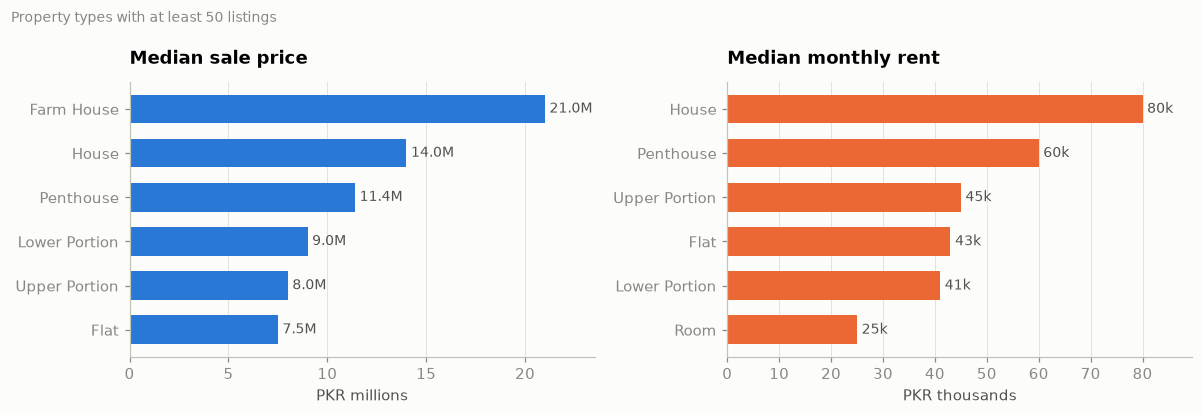

In [15]:
MIN_LISTINGS = 50   # medians from a handful of listings are not reliable

def median_by_type(data):
    g = data.groupby("property_type")["price"].agg(["median", "size"])
    return g[g["size"] >= MIN_LISTINGS]["median"].sort_values()

type_sale = median_by_type(sale) / 1e6
type_rent = median_by_type(rent) / 1e3

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].barh(type_sale.index, type_sale.values, color=SALE, height=0.65)
axes[0].set_title("Median sale price")
axes[0].set_xlabel("PKR millions")
label_bars(axes[0], "{:.1f}M")

axes[1].barh(type_rent.index, type_rent.values, color=RENT, height=0.65)
axes[1].set_title("Median monthly rent")
axes[1].set_xlabel("PKR thousands")
label_bars(axes[1], "{:.0f}k")

for ax in axes:
    horizontal(ax)
fig.suptitle(f"Property types with at least {MIN_LISTINGS} listings", x=0.01, ha="left",
             fontsize=9, color=MUTED)
plt.tight_layout()
plt.show()

**What this shows**

- A typical house sells for PKR 14.0M, almost twice a typical flat (PKR 7.5M). The same holds for rent: PKR 80k for a house against PKR 43k for a flat.
- Farm houses have the highest median sale price (PKR 21.0M), but with only 74 sale listings they are a tiny part of the market.
- Upper and lower portions sell and rent close to flat prices — they compete with flats, not with whole houses.

## 9. What drives the price?

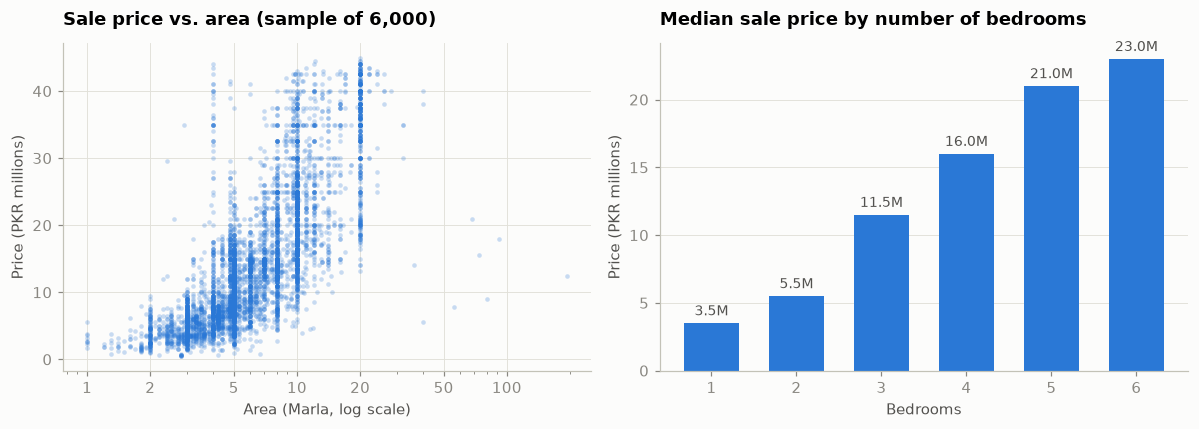

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

sample = sale.sample(6000, random_state=42)
axes[0].scatter(sample["area_marla"], sample["price"] / 1e6, s=9, alpha=0.25, color=SALE, linewidths=0)
axes[0].set_xscale("log")
axes[0].set_xticks([1, 2, 5, 10, 20, 50, 100], labels=["1", "2", "5", "10", "20", "50", "100"])
axes[0].set_title("Sale price vs. area (sample of 6,000)")
axes[0].set_xlabel("Area (Marla, log scale)")
axes[0].set_ylabel("Price (PKR millions)")

by_bed = sale[sale["bedrooms"] > 0].groupby("bedrooms")["price"].median() / 1e6
axes[1].bar(by_bed.index.astype(str), by_bed.values, color=SALE, width=0.65)
label_bars(axes[1], "{:.1f}M")
axes[1].grid(axis="x", visible=False)
axes[1].set_title("Median sale price by number of bedrooms")
axes[1].set_xlabel("Bedrooms")
axes[1].set_ylabel("Price (PKR millions)")

plt.tight_layout()
plt.show()

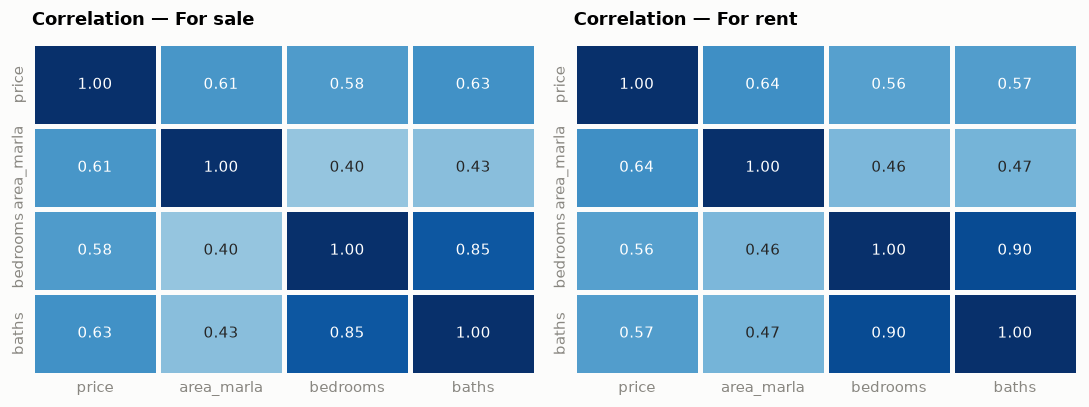

In [17]:
num_cols = ["price", "area_marla", "bedrooms", "baths"]

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for ax, (name, data) in zip(axes, [("For sale", sale), ("For rent", rent)]):
    sns.heatmap(data[num_cols].corr(), annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1,
                linewidths=2, linecolor="#fcfcfb", cbar=False, ax=ax)
    ax.set_title(f"Correlation — {name}")
    ax.tick_params(length=0)
plt.tight_layout()
plt.show()

**What this shows**

- Price rises steadily with every extra bedroom: from PKR 3.5M for 1 bedroom to PKR 23.0M for 6.
- For sales, area, bedrooms and bathrooms are all moderately correlated with price (0.61, 0.58 and 0.63). None of them explains price on its own — the scatter shows a wide price range at every size, which is the effect of location.
- For rents the picture is similar, with area the strongest single signal (0.64), ahead of bedrooms and bathrooms (0.56 and 0.57).
- Bedrooms and bathrooms move almost together (correlation 0.85 for sales), so in a model they carry largely the same information.

## 10. Most expensive and most affordable neighbourhoods

112 neighbourhoods have at least 100 sale listings


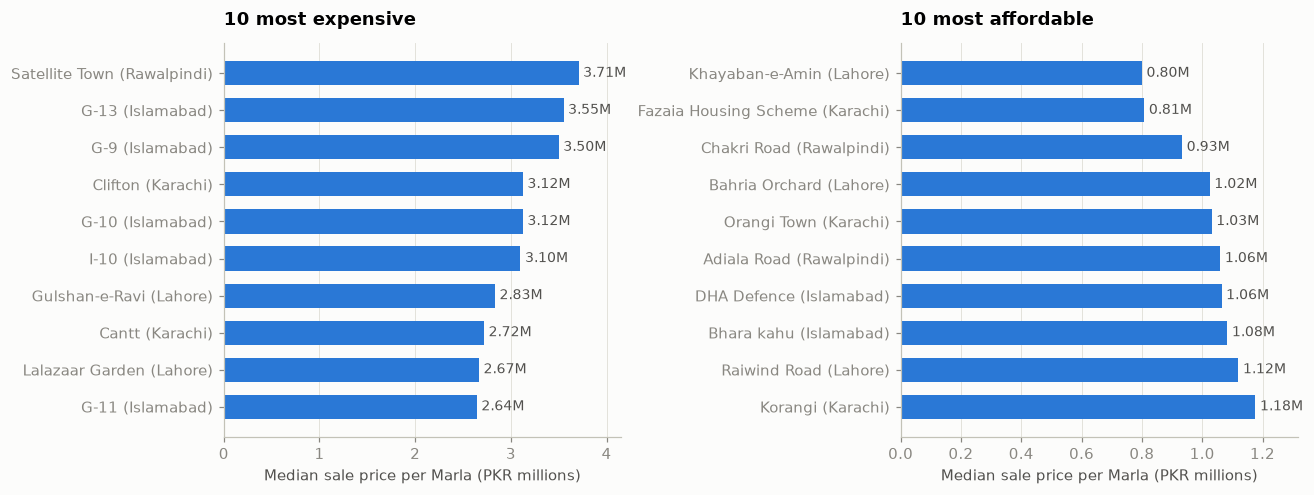

In [18]:
MIN_LOCATION_LISTINGS = 100

loc = (sale.groupby(["city", "location"])
           .agg(listings=("price", "size"),
                median_price_per_marla=("price_per_marla", "median"),
                median_price=("price", "median"))
           .query("listings >= @MIN_LOCATION_LISTINGS")
           .reset_index())
loc["label"] = loc["location"] + " (" + loc["city"] + ")"
print(f"{len(loc)} neighbourhoods have at least {MIN_LOCATION_LISTINGS} sale listings")

top = loc.nlargest(10, "median_price_per_marla").sort_values("median_price_per_marla")
bottom = loc.nsmallest(10, "median_price_per_marla").sort_values("median_price_per_marla", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
for ax, data, title in [(axes[0], top, "10 most expensive"), (axes[1], bottom, "10 most affordable")]:
    ax.barh(data["label"], data["median_price_per_marla"] / 1e6, color=SALE, height=0.65)
    label_bars(ax, "{:.2f}M")
    horizontal(ax)
    ax.set_title(title)
    ax.set_xlabel("Median sale price per Marla (PKR millions)")
plt.tight_layout()
plt.show()

**What this shows**

- The most expensive neighbourhood is **Satellite Town (Rawalpindi)** at PKR 3.7M per Marla; the most affordable is **Khayaban-e-Amin (Lahore)** at PKR 0.80M — a 5x gap for the same amount of land.
- Islamabad accounts for 5 of the 10 most expensive neighbourhoods, and Lahore for 3 of the 10 most affordable.
- Only neighbourhoods with at least 100 sale listings are ranked. Without that threshold the ranking is dominated by places with one or two unusual listings.

## 11. Market segments by city

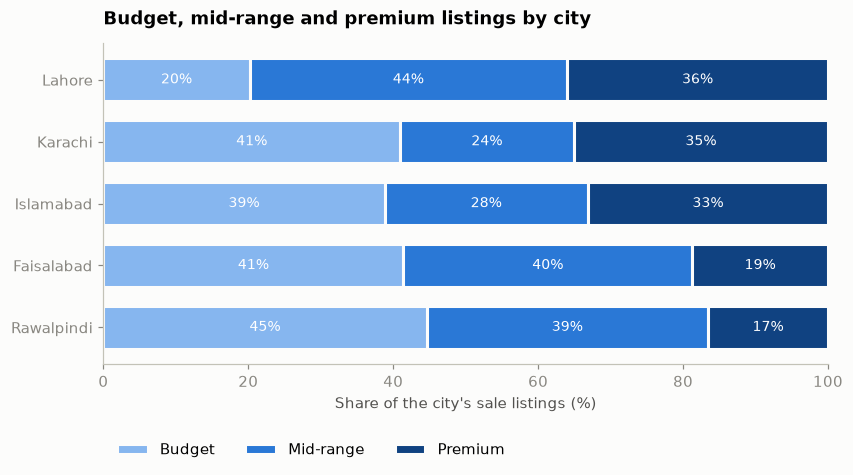

In [19]:
seg = pd.crosstab(sale["city"], sale["segment"], normalize="index") * 100
seg = seg.sort_values("Premium")

ax = seg.plot(kind="barh", stacked=True, figsize=(8.5, 3.8), width=0.7,
              color=SEGMENT_COLORS, edgecolor="#fcfcfb", linewidth=2)
for container in ax.containers:
    ax.bar_label(container, labels=[f"{v:.0f}%" for v in container.datavalues],
                 label_type="center", fontsize=9, color="white")
ax.grid(False)
ax.set_ylabel("")
ax.set_xlim(0, 100)
ax.set_xlabel("Share of the city's sale listings (%)")
ax.set_title("Budget, mid-range and premium listings by city")
ax.legend(title="", ncols=3, loc="upper left", bbox_to_anchor=(0, -0.2))
plt.show()

**What this shows**

Each segment holds one third of all sale listings, so a city with more than 33% in a segment is over-represented there.

- Lahore is the most premium-heavy market (36% of its listings), followed by Karachi (35%).
- Rawalpindi is the most budget-heavy (45% budget, only 17% premium).

## 12. Gross rental yield

A simple investor's question: how many percent of the purchase price does a year of rent bring in?

`gross yield = (median monthly rent per Marla x 12) / median sale price per Marla`

It is computed per city for houses and flats, the two types with enough listings on both sides. Lahore is missing because this extract has no rental listings for it.

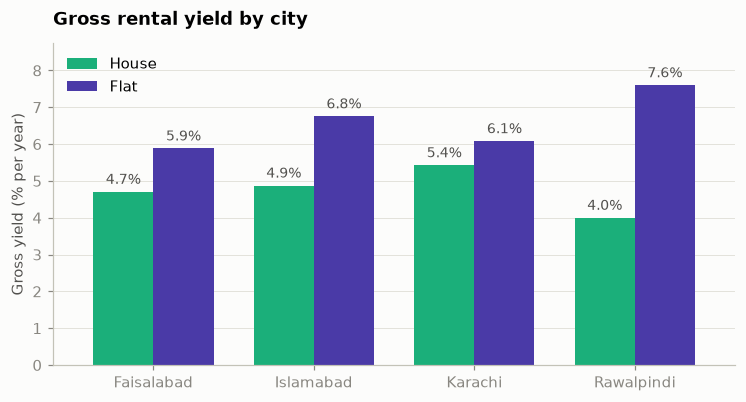

purpose                   median_rent_per_marla  median_sale_price_per_marla  \
city       property_type                                                       
Faisalabad Flat                        7,291.67                 1,487,500.00   
           House                       6,666.67                 1,700,000.00   
Islamabad  Flat                        8,421.05                 1,495,740.47   
           House                       8,125.00                 2,000,000.00   
Karachi    Flat                        7,931.03                 1,564,866.76   
           House                      10,750.00                 2,377,049.18   
Rawalpindi Flat                        8,333.33                 1,315,789.47   
           House                       5,833.33                 1,750,000.00   

purpose                   gross_yield_pct  
city       property_type                   
Faisalabad Flat                      5.88  
           House                     4.71  
Islamabad  Flat                      6.76  
           House                     4.88  
Karachi    Flat                      6.08  
           House                     5.43  
Rawalpindi Flat                      7.60  
           House                     4.00

In [20]:
ht = df[df["property_type"].isin(["House", "Flat"])]
yields = (ht.groupby(["city", "property_type", "purpose"])["price_per_marla"].median()
            .unstack("purpose").dropna())
yields["gross_yield_pct"] = yields["For Rent"] * 12 / yields["For Sale"] * 100

plot_data = yields["gross_yield_pct"].unstack("property_type")[["House", "Flat"]]
ax = plot_data.plot(kind="bar", figsize=(8, 3.8), width=0.75,
                    color=[TYPE_COLORS[c] for c in plot_data.columns])
label_bars(ax, "{:.1f}%")
ax.grid(axis="x", visible=False)
ax.set_xlabel("")
ax.set_ylabel("Gross yield (% per year)")
ax.tick_params(axis="x", rotation=0)
ax.margins(y=0.15)
ax.set_title("Gross rental yield by city")
ax.legend(title="")
plt.show()

yields.rename(columns={"For Rent": "median_rent_per_marla", "For Sale": "median_sale_price_per_marla"})

**What this shows**

- Gross yields range from 4.0% (houses in Rawalpindi) to 7.6% (flats in Rawalpindi).
- Flats yield more than houses in 4 of the 4 cities with rental data.

**Caveats:** this compares the median rental listing with the median sale listing, which are not the same properties. It is a gross figure based on asking prices — no taxes, maintenance or vacancy — so it is useful for comparing cities with each other, not as an expected return.

## 13. Key findings

1. **Sale and rent are two separate markets and must be analysed separately.** The typical sale listing is PKR 12.1M; the typical rent is PKR 50k per month.
2. **Lahore is the most expensive city to buy in on both measures**: median price PKR 14.0M and PKR 2.0M per Marla. The other four cities sit within a narrow band per Marla (PKR 1.69M to 1.79M).
3. **Location matters more than size.** Area, bedrooms and bathrooms each correlate only moderately with sale price (0.58–0.63), while price per Marla differs by 5x between the most and least expensive neighbourhoods.
4. **Houses cost about twice as much as flats** to buy (PKR 14.0M vs. PKR 7.5M) and to rent (PKR 80k vs. PKR 43k).
5. **Flats give a higher gross rental yield than houses in every city with rental data.** Yields range from 4.0% to 7.6% a year, with flats in Rawalpindi at the top.

## Limitations

- The analysis starts from an already-cleaned extract (99,499 listings). The most expensive properties were removed upstream (no sale above PKR 45M), so the luxury market is not covered.
- Lahore has no rental listings in this extract.
- Prices are asking prices from listings, not completed transactions.
- The extract has no dates, so price changes over time cannot be studied.

## Possible next steps

- Add the listing date and coordinates from the original Kaggle file to study seasonality and map prices.
- Build a price model using city, location, property type and area — the correlations above suggest location features will matter most.